# Task 2 — Random Forest Classifier & Feature Importance Analysis
**Pathline Training Academy — Machine Learning Internship**

## 1. Objective
Train a **Random Forest** classifier to predict whether a Titanic passenger survived, then **interpret** the model:
which input features drive its predictions, and do those drivers make sense?

The goal is not only a good accuracy score but an *explainable* model. Every preprocessing and modelling
choice below is written down together with the reason for it.

**Dataset:** Titanic passenger data — 891 passengers with their true survival outcome (`Survived`: 1 = survived, 0 = died).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)

df = pd.read_csv("../data/titanic.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Initial Data Inspection
Before any preprocessing, check the structure and quality of the data: data types, missing values,
value ranges and the balance of the target.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
missing = df.isna().sum()
print("Missing values per column:\n", missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["Survived"].value_counts(normalize=True).round(3))

Missing values per column:
 Age         177
Cabin       687
Embarked      2
dtype: int64

Duplicate rows: 0

Target distribution:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


**Findings**
* `Age` is missing for ~20% of passengers, `Cabin` for ~77%, `Embarked` for 2 passengers.
* No duplicate rows.
* The target is **moderately imbalanced**: about 62% died and 38% survived. This matters for evaluation —
  a model that always predicts "died" already scores ~62% accuracy, so that is the baseline to beat.

## 3. Feature Engineering
* **Dropped:** `PassengerId` (just a row number), `Name` and `Ticket` (free text / near-unique IDs that a tree would memorise rather than learn from).
* **`Cabin` → `HasCabin`**: the cabin number itself is missing for most people, but *whether* a cabin was recorded is informative (it was mostly recorded for wealthier passengers).
* **`FamilySize` = `SibSp` + `Parch` + 1**: total number of family members travelling together.
* **`Name` → `Title`**: the title inside the name (Mr, Mrs, Miss, Master, or Rare for Dr/Rev/Col…) captures sex, age group and
  social status at once — e.g. "Master" was used for young boys. Adding it raised cross-validation accuracy from about 0.81 to 0.83.
* **Categorical → numeric:** `Sex` becomes `Sex_male` (0/1); `Embarked` and `Title` are one-hot encoded, because scikit-learn models need numbers.

In [5]:
data = df.copy()
data["HasCabin"] = data["Cabin"].notna().astype(int)
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
title = data["Name"].str.extract(r",\s*([^\.]+)\.")[0]
title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
data["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
print(data["Title"].value_counts())
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

X = data.drop(columns="Survived")
y = data["Survived"]
X.head()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin,FamilySize,Title
0,3,male,22.0,1,0,7.2500,S,0,2,Mr
1,1,female,38.0,1,0,71.2833,C,1,2,Mrs
2,3,female,26.0,0,0,7.9250,S,0,1,Miss
3,1,female,35.0,1,0,53.1000,S,1,2,Mrs
4,3,male,35.0,0,0,8.0500,S,0,1,Mr


## 4. Train–Test Split (before filling missing values)
The data is split **before** any statistics (like the median age) are calculated. If the median were computed on the
full dataset, information from the test set would leak into training and make the test score look better than it really is.

`stratify=y` keeps the same 62/38 survival ratio in both sets.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Survival rate — train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (712, 10)  Test: (179, 10)
Survival rate — train: 0.383, test: 0.385


## 5. Preprocessing
### 5.1 Missing values
* `Age` → filled with the **median** of the *training set* (robust to outliers such as very old passengers).
* `Embarked` → filled with the **mode** (most common port) of the training set.

### 5.2 Why no scaling, log-transform or outlier removal?
Random Forests split on thresholds ("is Fare > 50?"), so they are **not affected by the scale or skew of a feature**.
Removing `Fare` outliers would also delete real, very wealthy passengers — exactly the people whose survival
pattern we want the model to learn. So these steps are deliberately skipped for this model.

In [7]:
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

def preprocess(frame):
    frame = frame.copy()
    frame["Age"] = frame["Age"].fillna(age_median)
    frame["Embarked"] = frame["Embarked"].fillna(embarked_mode)
    frame = pd.get_dummies(frame, columns=["Sex", "Embarked", "Title"], drop_first=True, dtype=int)
    return frame

X_train_p = preprocess(X_train)
X_test_p = preprocess(X_test).reindex(columns=X_train_p.columns, fill_value=0)
print("Age median used:", age_median, "| Embarked mode used:", embarked_mode)
print("Final features:", list(X_train_p.columns))

Age median used: 28.5 | Embarked mode used: S
Final features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


## 6. Baselines
A score only means something compared to a simple alternative:
1. **Majority class** — always predict "died".
2. **Gender rule** — predict "survived" for every woman, "died" for every man (the famous "women and children first" pattern).

In [8]:
from sklearn.metrics import accuracy_score

for name, X_, y_ in [("train", X_train, y_train), ("test", X_test, y_test)]:
    majority_acc = accuracy_score(y_, np.zeros_like(y_))
    gender_acc = accuracy_score(y_, (X_["Sex"] == "female").astype(int))
    print(f"[{name}] majority-class baseline: {majority_acc:.3f} | gender-rule baseline: {gender_acc:.3f}")

[train] majority-class baseline: 0.617 | gender-rule baseline: 0.789
[test] majority-class baseline: 0.615 | gender-rule baseline: 0.777


## 7. Training the Random Forest
Random Forest was chosen because it:
* captures non-linear relationships and interactions (e.g. *class × sex*) automatically,
* reduces overfitting by averaging many decorrelated decision trees (bagging + random feature subsets),
* provides built-in feature-importance scores.

Settings:
* `n_estimators=300` — 300 trees; more trees give more stable averages.
* `max_depth=6`, `min_samples_leaf=3` — limit tree size so the model learns general patterns instead of memorising individual passengers.
* `class_weight="balanced"` — gives the minority class (survivors) more weight, so the model doesn't simply favour "died".

5-fold **cross-validation** on the training set gives a more reliable estimate than a single split.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(rf_model, X_train_p, y_train, cv=cv, scoring="accuracy")
print("Cross-validation accuracy per fold:", cv_scores.round(3))
print(f"Mean CV accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

rf_model.fit(X_train_p, y_train)

Cross-validation accuracy per fold: [0.832 0.79  0.887 0.803 0.845]
Mean CV accuracy: 0.832 ± 0.034


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

## 8. Evaluation on the Held-out Test Set

Train accuracy: 0.861
Test accuracy:  0.804
Test ROC-AUC:   0.841

              precision    recall  f1-score   support

        Died       0.86      0.81      0.84       110
    Survived       0.72      0.80      0.76        69

    accuracy                           0.80       179
   macro avg       0.79      0.80      0.80       179
weighted avg       0.81      0.80      0.81       179



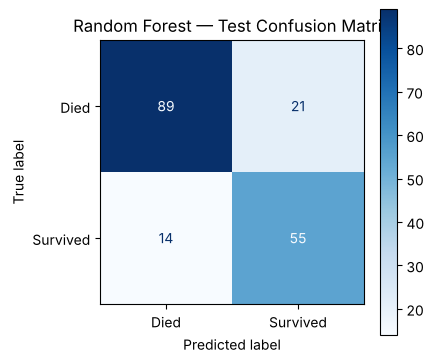

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

y_pred = rf_model.predict(X_test_p)
y_proba = rf_model.predict_proba(X_test_p)[:, 1]

train_acc = accuracy_score(y_train, rf_model.predict(X_train_p))
test_acc = accuracy_score(y_test, y_pred)
print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy:  {test_acc:.3f}")
print(f"Test ROC-AUC:   {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Died", "Survived"]))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Died", "Survived"], cmap="Blues", ax=ax)
ax.set_title("Random Forest — Test Confusion Matrix")
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()

**Reading the results**
* **Cross-validation accuracy 0.83 vs. 0.79 for the gender rule** on the training data, and **test accuracy 0.80 vs. 0.78** on unseen data — the model beats both baselines, though the gender rule alone is a strong baseline, which already hints that sex is the dominant signal.
* **ROC-AUC 0.84**: the model ranks a random survivor above a random non-survivor 84% of the time.
* **Recall for survivors is 0.80** — thanks to `class_weight="balanced"`, the minority class is not neglected.
* Train accuracy (0.86) and test accuracy (0.80) are close, so the depth limits worked and the model is **not overfitting**.
* About 80–83% is a realistic score for Titanic. A score of 100% would be a red flag for data leakage
  (e.g. a label that is derived directly from one of the inputs).

## 9. Feature Importance Analysis
Two complementary methods are used:

1. **Impurity-based importance (MDI)** — built into Random Forest: how much each feature reduces Gini impurity across all
   splits in all trees. Fast, but biased towards continuous / high-cardinality features such as `Fare` and `Age`
   (they offer many possible split points).
2. **Permutation importance** — computed on the *test set*: shuffle one feature at a time and measure how much accuracy drops.
   Slower, but model-agnostic, measured on unseen data, and less biased.

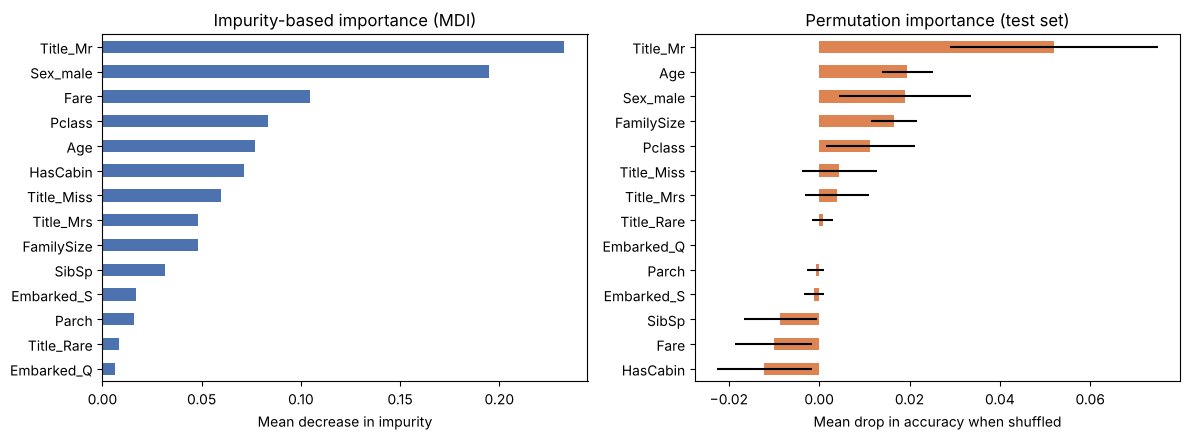

,MDI,Permutation
Title_Mr,0.233,0.052
Age,0.077,0.020
Sex_male,0.195,0.019
FamilySize,0.048,0.017
Pclass,0.084,0.011
Title_Miss,0.060,0.004
Title_Mrs,0.048,0.004
Title_Rare,0.008,0.001
Embarked_Q,0.006,0.000
Parch,0.016,-0.001


In [11]:
from sklearn.inspection import permutation_importance

mdi = pd.Series(rf_model.feature_importances_, index=X_train_p.columns).sort_values()

perm = permutation_importance(rf_model, X_test_p, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="accuracy")
perm_imp = pd.Series(perm.importances_mean, index=X_test_p.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mdi.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Impurity-based importance (MDI)")
axes[0].set_xlabel("Mean decrease in impurity")
perm_imp.plot(kind="barh", ax=axes[1], color="#DD8452",
              xerr=pd.Series(perm.importances_std, index=X_test_p.columns)[perm_imp.index])
axes[1].set_title("Permutation importance (test set)")
axes[1].set_xlabel("Mean drop in accuracy when shuffled")
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=120); plt.show()

pd.DataFrame({"MDI": mdi, "Permutation": perm_imp}).sort_values("Permutation", ascending=False).round(3)

## 10. Sanity-check the Top Features Against the Data
Feature importance says *how much* a feature matters, not *in which direction*. Looking at survival rates confirms the direction.

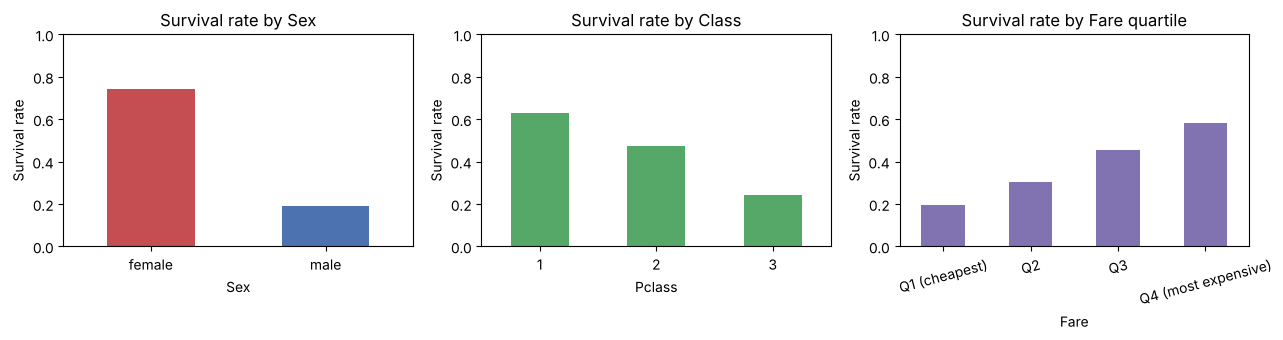

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby("Sex")["Survived"].mean().plot(kind="bar", ax=axes[0], color=["#C44E52", "#4C72B0"], rot=0)
axes[0].set_title("Survival rate by Sex")
df.groupby("Pclass")["Survived"].mean().plot(kind="bar", ax=axes[1], color="#55A868", rot=0)
axes[1].set_title("Survival rate by Class")
pd.qcut(df["Fare"], 4, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4 (most expensive)"]) \
  .pipe(lambda q: df.groupby(q, observed=True)["Survived"].mean()) \
  .plot(kind="bar", ax=axes[2], color="#8172B2", rot=15)
axes[2].set_title("Survival rate by Fare quartile")
for ax in axes: ax.set_ylabel("Survival rate"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig("images/survival_rates.png", dpi=120); plt.show()

print(df.groupby("Sex")["Survived"].mean().round(3))
print(df.groupby("Pclass")["Survived"].mean().round(3))

## 11. Interpretation
* **Gender is the strongest driver.** `Title_Mr` and `Sex_male` are the top features under both methods. Women survived at about 74%
  vs. about 19% for men — the "women and children first" evacuation policy. `Title_Mr` (adult man) is even more informative than
  `Sex_male` alone, because it also separates adult men from boys ("Master").
* **Age, family size and class follow.** Children were prioritised, very large families had low survival, and first-class
  passengers survived at ~63% vs. ~24% in third class.
* **`Fare` and `HasCabin` look important under MDI but near zero under permutation importance.** Two reasons:
  (1) MDI is biased toward continuous features with many split points, such as `Fare`;
  (2) both features carry the same "wealth" information as `Pclass`, so when one is shuffled the model can fall back on the others.
* **Correlated features split their importance** — `Sex_male`/`Title_Mr` and `Pclass`/`Fare`/`HasCabin` — so importance should be
  read per *group of related features*, not only per individual column.

## 12. Conclusion
The Random Forest reaches **0.83 cross-validation accuracy and 0.80 test accuracy (ROC-AUC 0.84)**, beating both a majority-class
and a gender-only baseline without overfitting. The feature-importance analysis shows the model learned historically sensible
patterns (gender, age, class) rather than spurious ones. Comparing two importance methods showed why one chart alone can mislead:
impurity-based importance overstated `Fare`, while permutation importance on unseen data gave the more reliable picture.

**Possible next steps:** tune hyper-parameters with `GridSearchCV`, extract passenger titles (Mr/Mrs/Master) from `Name`,
and use SHAP values to explain individual predictions.